In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/desolution01/messy-employee-dataset/Messy_Employee_dataset.csv


In [5]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("desolution01/messy-employee-dataset")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/desolution01/messy-employee-dataset


In [6]:
data = pd.read_csv("/kaggle/input/datasets/desolution01/messy-employee-dataset/Messy_Employee_dataset.csv")

In [7]:
df = data.copy()

In [8]:
df


,Employee_ID,First_Name,Last_Name,Age,Department_Region,Status,Join_Date,Salary,Email,Phone,Performance_Score,Remote_Work
0,EMP1000,Bob,Davis,25.0,DevOps-California,Active,4/2/2021,59767.65,bob.davis@example.com,-1651623197,Average,True
1,EMP1001,Bob,Brown,NaN,Finance-Texas,Active,7/10/2020,65304.66,bob.brown@example.com,-1898471390,Excellent,True
2,EMP1002,Alice,Jones,NaN,Admin-Nevada,Pending,12/7/2023,88145.90,alice.jones@example.com,-5596363211,Good,True
3,EMP1003,Eva,Davis,25.0,Admin-Nevada,Inactive,11/27/2021,69450.99,eva.davis@example.com,-3476490784,Good,True
4,EMP1004,Frank,Williams,25.0,Cloud Tech-Florida,Active,1/5/2022,109324.61,frank.williams@example.com,-1586734256,Poor,False
...,...,...,...,...,...,...,...,...,...,...,...,...
1015,EMP2015,David,Miller,30.0,HR-California,Active,8/19/2023,NaN,david.miller@example.com,-3546212759,Good,True
1016,EMP2016,David,Johnson,30.0,Cloud Tech-Texas,Inactive,11/7/2021,100215.06,david.johnson@example.com,-2508261122,Good,True
1017,EMP2017,Charlie,Williams,40.0,Finance-New York,Active,10/4/2023,114587.11,charlie.williams@example.com,-1261632487,Average,False
1018,EMP2018,Alice,Garcia,30.0,HR-Florida,Inactive,12/16/2024,71318.79,alice.garcia@example.com,-8995729892,Good,True


In [9]:
df.info

<bound method DataFrame.info of      Employee_ID First_Name Last_Name   Age   Department_Region    Status  \
0        EMP1000        Bob     Davis  25.0   DevOps-California    Active   
1        EMP1001        Bob     Brown   NaN       Finance-Texas    Active   
2        EMP1002      Alice     Jones   NaN        Admin-Nevada   Pending   
3        EMP1003        Eva     Davis  25.0        Admin-Nevada  Inactive   
4        EMP1004      Frank  Williams  25.0  Cloud Tech-Florida    Active   
...          ...        ...       ...   ...                 ...       ...   
1015     EMP2015      David    Miller  30.0       HR-California    Active   
1016     EMP2016      David   Johnson  30.0    Cloud Tech-Texas  Inactive   
1017     EMP2017    Charlie  Williams  40.0    Finance-New York    Active   
1018     EMP2018      Alice    Garcia  30.0          HR-Florida  Inactive   
1019     EMP2019      Heidi     Jones  30.0     DevOps-Illinois   Pending   

       Join_Date     Salary                

In [10]:
df.drop_duplicates

<bound method DataFrame.drop_duplicates of      Employee_ID First_Name Last_Name   Age   Department_Region    Status  \
0        EMP1000        Bob     Davis  25.0   DevOps-California    Active   
1        EMP1001        Bob     Brown   NaN       Finance-Texas    Active   
2        EMP1002      Alice     Jones   NaN        Admin-Nevada   Pending   
3        EMP1003        Eva     Davis  25.0        Admin-Nevada  Inactive   
4        EMP1004      Frank  Williams  25.0  Cloud Tech-Florida    Active   
...          ...        ...       ...   ...                 ...       ...   
1015     EMP2015      David    Miller  30.0       HR-California    Active   
1016     EMP2016      David   Johnson  30.0    Cloud Tech-Texas  Inactive   
1017     EMP2017    Charlie  Williams  40.0    Finance-New York    Active   
1018     EMP2018      Alice    Garcia  30.0          HR-Florida  Inactive   
1019     EMP2019      Heidi     Jones  30.0     DevOps-Illinois   Pending   

       Join_Date     Salary     

In [11]:
df.isnull().sum()

Employee_ID            0
First_Name             0
Last_Name              0
Age                  211
Department_Region      0
Status                 0
Join_Date              0
Salary                24
Email                  0
Phone                  0
Performance_Score      0
Remote_Work            0
dtype: int64

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Employee_ID        1020 non-null   object 
 1   First_Name         1020 non-null   object 
 2   Last_Name          1020 non-null   object 
 3   Age                809 non-null    float64
 4   Department_Region  1020 non-null   object 
 5   Status             1020 non-null   object 
 6   Join_Date          1020 non-null   object 
 7   Salary             996 non-null    float64
 8   Email              1020 non-null   object 
 9   Phone              1020 non-null   int64  
 10  Performance_Score  1020 non-null   object 
 11  Remote_Work        1020 non-null   bool   
dtypes: bool(1), float64(2), int64(1), object(8)
memory usage: 88.8+ KB


In [13]:
df = df.drop("Email",axis = 1)




In [14]:
df

,Employee_ID,First_Name,Last_Name,Age,Department_Region,Status,Join_Date,Salary,Phone,Performance_Score,Remote_Work
0,EMP1000,Bob,Davis,25.0,DevOps-California,Active,4/2/2021,59767.65,-1651623197,Average,True
1,EMP1001,Bob,Brown,NaN,Finance-Texas,Active,7/10/2020,65304.66,-1898471390,Excellent,True
2,EMP1002,Alice,Jones,NaN,Admin-Nevada,Pending,12/7/2023,88145.90,-5596363211,Good,True
3,EMP1003,Eva,Davis,25.0,Admin-Nevada,Inactive,11/27/2021,69450.99,-3476490784,Good,True
4,EMP1004,Frank,Williams,25.0,Cloud Tech-Florida,Active,1/5/2022,109324.61,-1586734256,Poor,False
...,...,...,...,...,...,...,...,...,...,...,...
1015,EMP2015,David,Miller,30.0,HR-California,Active,8/19/2023,NaN,-3546212759,Good,True
1016,EMP2016,David,Johnson,30.0,Cloud Tech-Texas,Inactive,11/7/2021,100215.06,-2508261122,Good,True
1017,EMP2017,Charlie,Williams,40.0,Finance-New York,Active,10/4/2023,114587.11,-1261632487,Average,False
1018,EMP2018,Alice,Garcia,30.0,HR-Florida,Inactive,12/16/2024,71318.79,-8995729892,Good,True


In [15]:
df.drop(columns=["Phone", "Department_Region", "First_Name", "Last_Name"], inplace=True)

In [16]:
df.drop(columns = ["Employee_ID"], inplace=True)

In [17]:
df

,Age,Status,Join_Date,Salary,Performance_Score,Remote_Work
0,25.0,Active,4/2/2021,59767.65,Average,True
1,NaN,Active,7/10/2020,65304.66,Excellent,True
2,NaN,Pending,12/7/2023,88145.90,Good,True
3,25.0,Inactive,11/27/2021,69450.99,Good,True
4,25.0,Active,1/5/2022,109324.61,Poor,False
...,...,...,...,...,...,...
1015,30.0,Active,8/19/2023,NaN,Good,True
1016,30.0,Inactive,11/7/2021,100215.06,Good,True
1017,40.0,Active,10/4/2023,114587.11,Average,False
1018,30.0,Inactive,12/16/2024,71318.79,Good,True


In [18]:
import seaborn as sns
import matplotlib.pyplot as plt
df.columns

Index(['Age', 'Status', 'Join_Date', 'Salary', 'Performance_Score',
       'Remote_Work'],
      dtype='object')

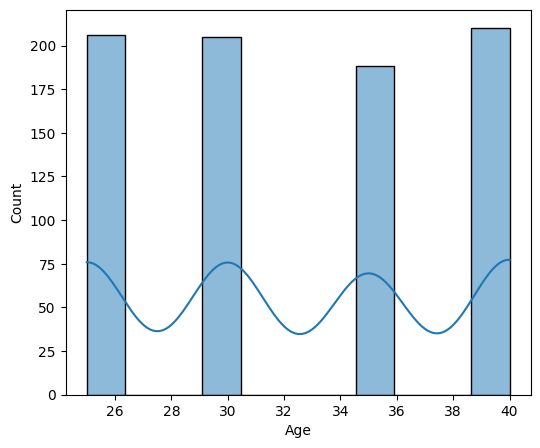

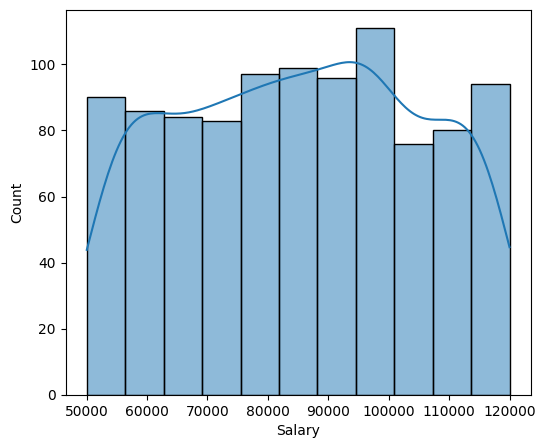

In [19]:
numeric_cols = ['Age','Salary']
for cols in numeric_cols:
    plt.figure(figsize=(6,5))
    sns.histplot(df[cols],kde = True)

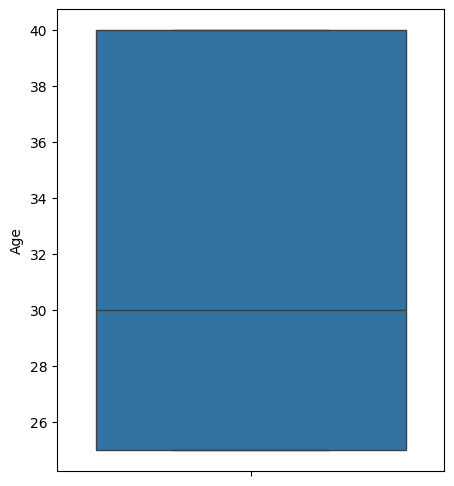

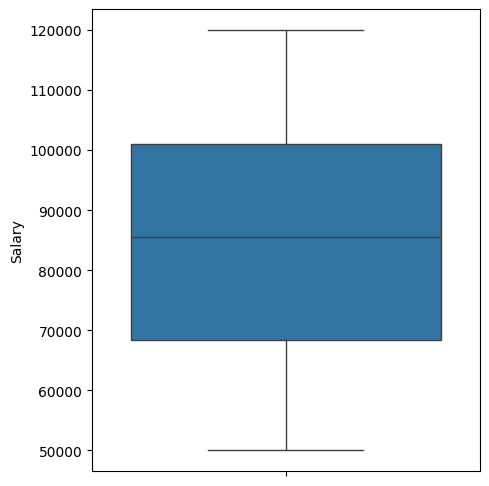

In [20]:
for cols in numeric_cols:
    plt.figure(figsize = (5,6))
    sns.boxplot(df[cols])

In [21]:
df.dropna(inplace = True)

In [22]:
df

,Age,Status,Join_Date,Salary,Performance_Score,Remote_Work
0,25.0,Active,4/2/2021,59767.65,Average,True
3,25.0,Inactive,11/27/2021,69450.99,Good,True
4,25.0,Active,1/5/2022,109324.61,Poor,False
5,40.0,Inactive,6/10/2020,88642.84,Good,False
7,30.0,Inactive,7/17/2022,94497.91,Average,True
...,...,...,...,...,...,...
1014,30.0,Pending,5/16/2021,51990.98,Excellent,True
1016,30.0,Inactive,11/7/2021,100215.06,Good,True
1017,40.0,Active,10/4/2023,114587.11,Average,False
1018,30.0,Inactive,12/16/2024,71318.79,Good,True


In [23]:
df.drop(columns = ["Join_Date"],inplace = True)

In [24]:
df

,Age,Status,Salary,Performance_Score,Remote_Work
0,25.0,Active,59767.65,Average,True
3,25.0,Inactive,69450.99,Good,True
4,25.0,Active,109324.61,Poor,False
5,40.0,Inactive,88642.84,Good,False
7,30.0,Inactive,94497.91,Average,True
...,...,...,...,...,...
1014,30.0,Pending,51990.98,Excellent,True
1016,30.0,Inactive,100215.06,Good,True
1017,40.0,Active,114587.11,Average,False
1018,30.0,Inactive,71318.79,Good,True


In [25]:
df = pd.get_dummies(df,drop_first = True)

In [26]:
df

,Age,Salary,Remote_Work,Status_Inactive,Status_Pending,Performance_Score_Excellent,Performance_Score_Good,Performance_Score_Poor
0,25.0,59767.65,True,False,False,False,False,False
3,25.0,69450.99,True,True,False,False,True,False
4,25.0,109324.61,False,False,False,False,False,True
5,40.0,88642.84,False,True,False,False,True,False
7,30.0,94497.91,True,True,False,False,False,False
...,...,...,...,...,...,...,...,...
1014,30.0,51990.98,True,False,True,True,False,False
1016,30.0,100215.06,True,True,False,False,True,False
1017,40.0,114587.11,False,False,False,False,False,False
1018,30.0,71318.79,True,True,False,False,True,False


In [27]:
df.astype(int)

,Age,Salary,Remote_Work,Status_Inactive,Status_Pending,Performance_Score_Excellent,Performance_Score_Good,Performance_Score_Poor
0,25,59767,1,0,0,0,0,0
3,25,69450,1,1,0,0,1,0
4,25,109324,0,0,0,0,0,1
5,40,88642,0,1,0,0,1,0
7,30,94497,1,1,0,0,0,0
...,...,...,...,...,...,...,...,...
1014,30,51990,1,0,1,1,0,0
1016,30,100215,1,1,0,0,1,0
1017,40,114587,0,0,0,0,0,0
1018,30,71318,1,1,0,0,1,0


<Axes: >

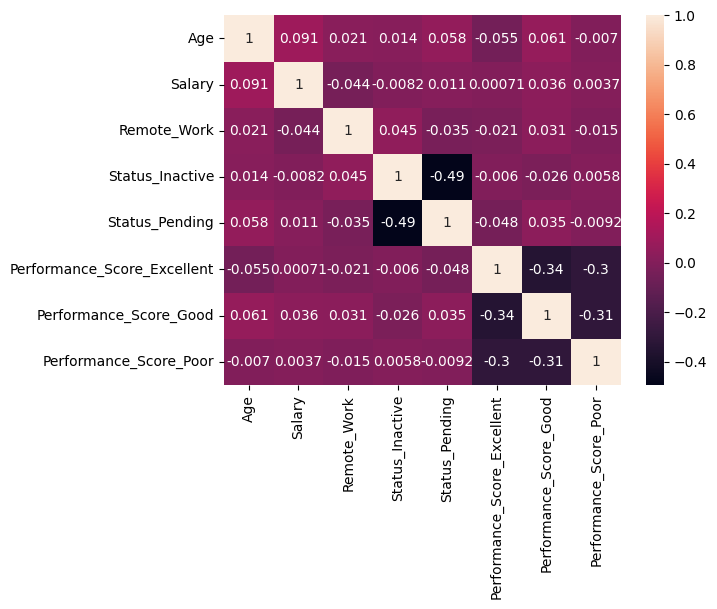

In [28]:
sns.heatmap(df.corr(numeric_only = True),annot = True)

In [29]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()


In [30]:
df.columns

Index(['Age', 'Salary', 'Remote_Work', 'Status_Inactive', 'Status_Pending',
       'Performance_Score_Excellent', 'Performance_Score_Good',
       'Performance_Score_Poor'],
      dtype='object')

In [31]:
cols = ['Age', 'Salary', 'Remote_Work', 'Status_Inactive', 'Status_Pending',
       'Performance_Score_Excellent', 'Performance_Score_Good',
       'Performance_Score_Poor']

In [32]:
df[cols] = sc.fit_transform(df[cols])

In [33]:
df

,Age,Salary,Remote_Work,Status_Inactive,Status_Pending,Performance_Score_Excellent,Performance_Score_Good,Performance_Score_Poor
0,-1.322503,-1.263388,0.988629,-0.664373,-0.743148,-0.581752,-0.589578,-0.518994
3,-1.322503,-0.779275,0.988629,1.505178,-0.743148,-0.581752,1.696127,-0.518994
4,-1.322503,1.214182,-1.011502,-0.664373,-0.743148,-0.581752,-0.589578,1.926804
5,1.332624,0.180210,-1.011502,1.505178,-0.743148,-0.581752,1.696127,-0.518994
7,-0.437460,0.472930,0.988629,1.505178,-0.743148,-0.581752,-0.589578,-0.518994
...,...,...,...,...,...,...,...,...
1014,-0.437460,-1.652178,0.988629,-0.664373,1.345628,1.718946,-0.589578,-0.518994
1016,-0.437460,0.758755,0.988629,1.505178,-0.743148,-0.581752,1.696127,-0.518994
1017,1.332624,1.477277,-1.011502,-0.664373,-0.743148,-0.581752,-0.589578,-0.518994
1018,-0.437460,-0.685896,0.988629,1.505178,-0.743148,-0.581752,1.696127,-0.518994


In [34]:
from scipy.stats import pearsonr
df.columns


Index(['Age', 'Salary', 'Remote_Work', 'Status_Inactive', 'Status_Pending',
       'Performance_Score_Excellent', 'Performance_Score_Good',
       'Performance_Score_Poor'],
      dtype='object')

In [35]:
selected_features = ['Age', 'Salary', 'Remote_Work', 'Status_Inactive', 'Status_Pending',
       'Performance_Score_Excellent', 'Performance_Score_Good',
       'Performance_Score_Poor']

In [43]:
correlations = {
    features : pearsonr(df[features],df['Salary'])[0]
    for features in selected_features
}
correlations_df = pd.DataFrame(correlations.items(),columns = ['features','pearsonr'])
correlations_df.sort_values(by = 'pearsonr',ascending = True)

,features,pearsonr
2,Remote_Work,-0.043894
3,Status_Inactive,-0.008182
5,Performance_Score_Excellent,0.000708
7,Performance_Score_Poor,0.003666
4,Status_Pending,0.011327
6,Performance_Score_Good,0.036386
0,Age,0.091204
1,Salary,1.000000


In [46]:
from scipy.stats import chi2_contingency
contingency_table = pd.crosstab(df['Salary'],df['Remote_Work'])
chi2,p_value,dof,expected = chi2_contingency(contingency_table)

In [3]:
!git clone https://github.com/kaiserboyri10-cell/Basic-Machine-learning-with-EDA-.git

Cloning into 'Basic-Machine-learning-with-EDA-'...
fatal: unable to access 'https://github.com/kaiserboyri10-cell/Basic-Machine-learning-with-EDA-.git/': Could not resolve host: github.com


In [2]:
%cd Basic-Machine-learning-with-EDA-

[Errno 2] No such file or directory: 'Basic-Machine-learning-with-EDA-'
/kaggle/working


In [4]:
!git config --global user.name "Shivansh"
!git config --global user.email "kaiserboyri10@gmail.com"

In [5]:
!git add .
!git commit -m "Added ML EDA project"
!git push

fatal: not a git repository (or any parent up to mount point /kaggle)
Stopping at filesystem boundary (GIT_DISCOVERY_ACROSS_FILESYSTEM not set).
fatal: not a git repository (or any parent up to mount point /kaggle)
Stopping at filesystem boundary (GIT_DISCOVERY_ACROSS_FILESYSTEM not set).
fatal: not a git repository (or any parent up to mount point /kaggle)
Stopping at filesystem boundary (GIT_DISCOVERY_ACROSS_FILESYSTEM not set).
